In [1]:
import numpy as np
import matplotlib.pyplot as plt
import edos
from matplotlib import rcParams
from scipy.integrate import solve_ivp

In [2]:
#fonte LaTex

rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Computer Modern Roman"], 
    "axes.labelsize": 16,  
    "font.size": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16
})

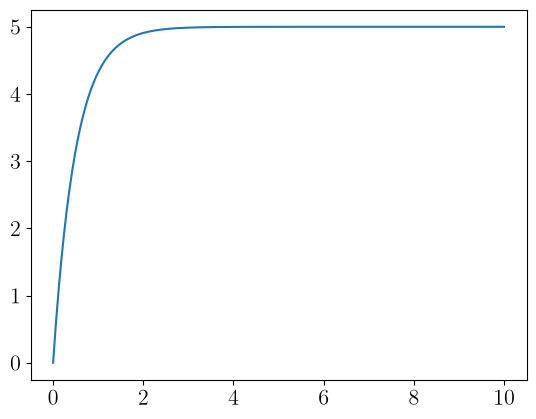

In [3]:
#4 Definindo a queda livre

g = 10 #(m/s^2)
va = 5 #(m/s)

def f(t, y):
    v = y
    dvdt = g - g/va * v

    return dvdt

t_eval = np.linspace(0,10,500)
v0 = 0

solution = edos.RK4(fun=f, y0=v0, t_eval=t_eval)
plt.plot(t_eval, solution)
plt.show()

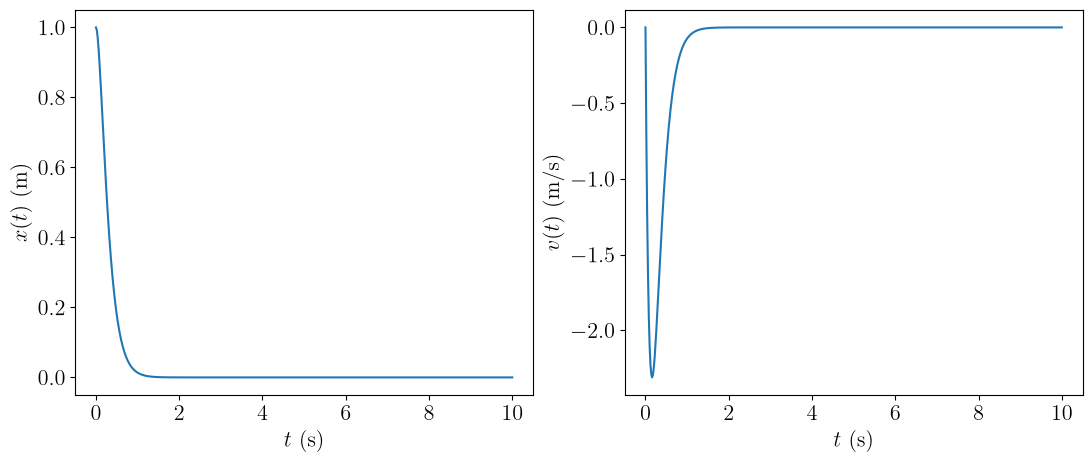

In [6]:
#Oscilador

gamma = 1
omega0 = 2*np.pi

def oscilador(t, y):

    x, v = y
    dxdt = v
    dvdt = -omega0**2 * x - 2*gamma*omega0*v

    return np.array([dxdt, dvdt])


t_eval = np.linspace(0,10,500)
y0 = np.array([1, 0])

solution = edos.RK4(oscilador, y0=y0, t_eval=t_eval)
x = solution[:,0]
v = solution[:,1]

plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
plt.plot(t_eval, x)
plt.xlabel(r'$t$ (s)')
plt.ylabel(r'$x(t)$ (m)')

plt.subplot(1,2,2)
plt.plot(t_eval, v)
plt.xlabel(r'$t$ (s)')
plt.ylabel(r'$v(t)$ (m/s)')
plt.show()


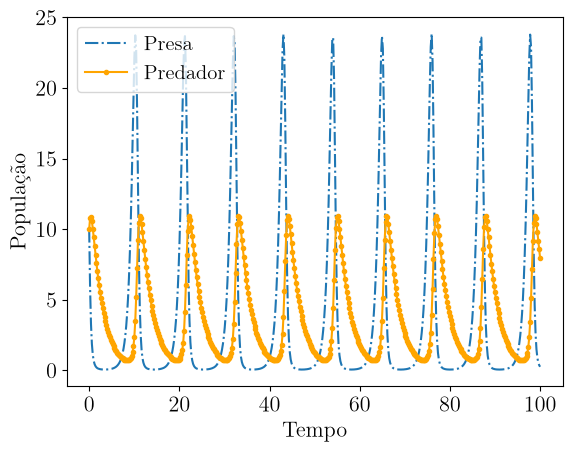

In [ ]:
#6 Lotka-Volterra
alpha, beta, delta, gamma = 1.5, 0.4, 0.1, 0.4

t_eval = np.linspace(0,100,500)

def lotka_volterra(t, Y):
    x, y = Y
    dxdt = alpha*x - beta*x*y
    dydt = delta*x*y - gamma*y

    return dxdt, dydt

sol = solve_ivp(fun=lotka_volterra, t_eval=t_eval, t_span=(0,100), y0=[10,10])
x = sol.y[0]
y = sol.y[1]

plt.plot(sol.t, x, label="Presa", linestyle="-.")
plt.plot(sol.t, y, label="Predador", color="orange", marker="o", markersize=3)
plt.ylabel("População")
plt.xlabel("Tempo")
plt.legend()
plt.show()


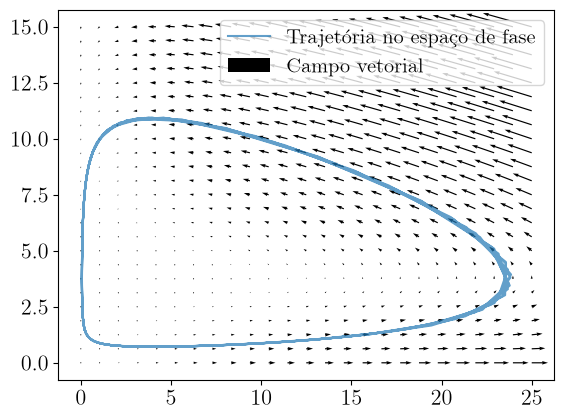

In [ ]:
X = np.linspace(0,25,25)
Y = np.linspace(0,15,25)

X, Y = np.meshgrid(X,Y)

u = alpha*X - beta*X*Y
v = delta*X*Y - gamma*Y

plt.plot(x, y, label="Trajetória no espaço de fase", alpha=0.7)
plt.quiver(X, Y, u, v, color="black", label="Campo vetorial")
plt.legend()
plt.show()

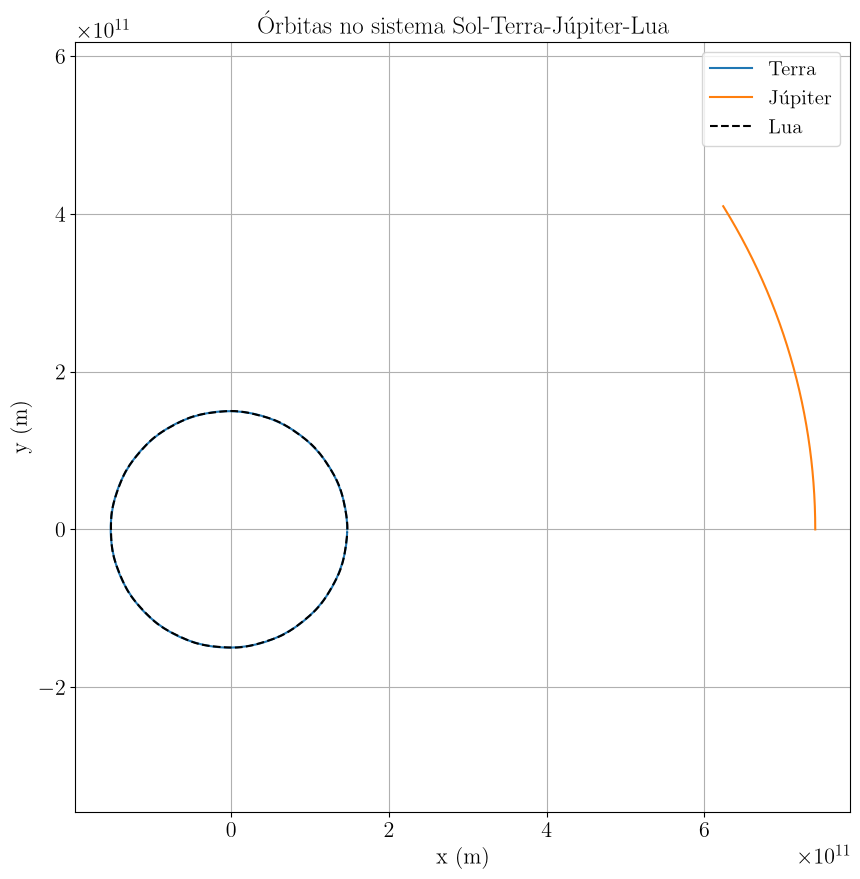

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Constantes e massas 
G = 6.67430e-11
Ms = 1.989e30       # Massa do Sol (kg)
Ml = 7.34767e22       # Massa da Lua (kg)
M5 = 1.8982e27       # Massa de Júpiter (kg)
M3 = 5.9722e24      # Massa da Terra (kg) (x50^3 para melhorar a visualização das órbitas)

# Condições iniciais 
# Terra: posição e velocidade em relação ao Sol
p3, vp3 = 1.47095e11, 30.31e3

# Júpiter: posição e velocidade em relação ao Sol
p5, vp5 = 7.40595e11, 13.72e3

dia = 24*3600

# Lua: posição e velocidade em relação ao Sol
pLT = 3.633e8  #Distância média da Lua à Terra (m) (x50 para melhorar a visualização das órbitas)
pL = pLT + p3      # Distância Lua-Sol (m)
vL = vp3 + 2*np.pi*pLT/(27*dia)      # Velocidade orbital (m/s)

# Estado inicial:
# [x3, y3, x5, y5, xl, yl, vx3, vy3, vx5, vy5, vxl, vyl]
y0 = [
    p3, 0,                  # Terra
    p5, 0,                  # Júpiter
    pL, 0,                # Lua
    0, vp3,                 # Velocidade da Terra
    0, vp5,                 # Velocidade de Júpiter
    0, vL               # Velocidade da Lua
]

def orbitas(t, y):

    x3, y3, x5, y5, xl, yl, vx3, vy3, vx5, vy5, vxl, vyl = y

    dx3dt, dy3dt = vx3, vy3
    dx5dt, dy5dt = vx5, vy5
    dxldt, dyldt = vxl, vyl

    # Aceleração da Terra
    ax3 = (
        -G*Ms*x3/(x3**2 + y3**2)**1.5
        -G*Ml*(x3-xl)/((x3-xl)**2 + (y3-yl)**2)**1.5
        -G*M5*(x3-x5)/((x3-x5)**2 + (y3-y5)**2)**1.5
    )

    ay3 = (
        -G*Ms*y3/(x3**2 + y3**2)**1.5
        -G*Ml*(y3-yl)/((x3-xl)**2 + (y3-yl)**2)**1.5
        -G*M5*(y3-y5)/((x3-x5)**2 + (y3-y5)**2)**1.5
    )

    # Aceleração de Júpiter
    ax5 = (
        -G*Ms*x5/(x5**2 + y5**2)**1.5
        -G*Ml*(x5-xl)/((x5-xl)**2 + (y5-yl)**2)**1.5
        -G*M3*(x5-x3)/((x5-x3)**2 + (y5-y3)**2)**1.5
    )

    ay5 = (
        -G*Ms*y5/(x5**2 + y5**2)**1.5
        -G*Ml*(y5-yl)/((x5-xl)**2 + (y5-yl)**2)**1.5
        -G*M3*(y5-y3)/((x5-x3)**2 + (y5-y3)**2)**1.5
    )

    # Aceleração da Lua
    axl = (
        -G*Ms*xl/(xl**2 + yl**2)**1.5
        -G*M3*(xl-x3)/((xl-x3)**2 + (yl-y3)**2)**1.5
        -G*M5*(xl-x5)/((xl-x5)**2 + (yl-y5)**2)**1.5
    )

    ayl = (
        -G*Ms*yl/(xl**2 + yl**2)**1.5
        -G*M3*(yl-y3)/((xl-x3)**2 + (yl-y3)**2)**1.5
        -G*M5*(yl-y5)/((xl-x5)**2 + (yl-y5)**2)**1.5
    )

    return np.array([dx3dt, dy3dt, dx5dt, dy5dt, dxldt, dyldt,
                      ax3, ay3, ax5, ay5, axl, ayl])


t_eval = np.linspace(0, dia*365, 10000)

solution = solve_ivp(
    fun=orbitas,
    t_span=(0, dia*365),
    y0=y0,
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-3
)

# Gráfico das órbitas
plt.figure(figsize=(10, 10))

plt.plot(solution.y[0], solution.y[1], label="Terra")
plt.plot(solution.y[2], solution.y[3], label="Júpiter")
plt.plot(solution.y[4], solution.y[5], label="Lua", linestyle="--", color="black")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Órbitas no sistema Sol-Terra-Júpiter-Lua")
plt.axis("equal")
plt.legend()
plt.grid()
plt.show()